# Légume'Ami — Soil Intelligence: Castelnaudary case study

**Model-estimated erosion potential and computed soil vulnerability for a real field in the Lauragais (Aude, France).**

This notebook executes the quantitative Soil Intelligence pipeline end to end on **real downloaded datasets** and the bounded `/geo` API. Every number and figure below is produced by the code in this notebook — nothing is illustrative.

## Methodology panel (provenance, stated once)

**Real inputs for the study area:**
- **Copernicus DEM GLO-30** → terrain slope (LS factor).
- **ISRIC SoilGrids 2.0** → sand / silt / clay / organic carbon / pH (K factor). 250 m modelled estimates.
- **Copernicus Sentinel-2 L2A** → NDVI vegetation-cover fraction (one low-cloud scene).
- **ERA5 2015–2024** (Open-Meteo archive) → historical rainfall exposure series.
- **IGN RPG 2024** → declared crop / parcel category.

**Two complementary indicators:**
1. An **exploratory soil-vulnerability index (0–100)** from normalised exposure proxies with documented weights — an *exposure* indicator, not a soil-loss rate.
2. A **quantitative RUSLE model** `A = R · K · LS · C · P` in t ha⁻¹ yr⁻¹, giving a **model-estimated** long-term annual erosion potential.

**RUSLE parameter provenance:** R and C are literature-derived (Panagos et al. 2015); K uses the Williams (1995) EPIC estimator from SoilGrids texture + organic carbon; LS uses McCool (1987) for steepness with the RUSLE slope-length relation. `P = 1` is the documented baseline when no support practice is declared. Where a parameter is uncertain we use an **explicit range and scenario/sensitivity analysis** rather than a silent assumption.

**What this is:** a transparent, reproducible research prototype. The RUSLE output is a legitimate *model estimate* of erosion potential, not a field measurement, and its coverage is a **single study area** (Castelnaudary) — not all of France.

In [1]:
# --- Setup: make the repository importable regardless of notebook cwd ---
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent  # executed from notebooks/
assert (ROOT / "src").exists(), f"repo root not found from {Path.cwd()}"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Repo root:", ROOT)

Repo root: /home/ubuntu/Downloads/LegumAmies


## 1. Execute the case study and (re)generate all numeric outputs + figures

`experiments/geo/soil_report.py` runs the full pipeline on the real inputs and writes `reports/soil-intelligence/` (JSON/CSV results, `experiment.log`, `RESULTS.md`, and six 300 dpi PNG + SVG figures). Re-running it here guarantees the figures and tables match the executed numbers.

In [2]:
import importlib
import experiments.geo.soil_report as soil_report
importlib.reload(soil_report)

res = soil_report.main()  # executes the pipeline and saves artifacts
print("\nModel:", res["model_version"], "|", res["equation"])
print("Study area:", res["study_area"]["name"], "| coverage:", res["study_area"]["coverage"])

2026-11-01 06:20:11,701 INFO study_area=Castelnaudary / Lauragais (Aude, FR)


2026-11-01 06:20:11,701 INFO inputs slope={'mean_deg': 2.72, 'p90_deg': 6.06, 'max_deg': 23.41} soil={'clay_pct': 31.1, 'sand_pct': 26.3, 'silt_pct': 42.6, 'oc_plough_pct': 2.27, 'ph_h2o': 7.43} ndvi_cover=0.728 rain={'years': 10, 'annual_precip_mm_mean': np.float64(909.0), 'heavy_rain_days_gt20mm_per_year': 5.6, 'max_daily_precip_mm': 60.9}


2026-11-01 06:20:11,702 INFO vulnerability=40.5 (modéré)


2026-11-01 06:20:11,702 INFO RUSLE baseline A=6.68 t/ha/yr (K=0.0341 LS=0.9797)


2026-11-01 06:20:13,230 INFO Saved figures: ['01_scenario_comparison.png', '02_factor_breakdown.png', '03_tornado_sensitivity.png', '04_rainfall_exposure_timeseries.png', '05_soil_slope_maps.png', '06_uncertainty_range.png']


2026-11-01 06:20:13,231 INFO DONE



Model: rusle-1.0.0 | A = R * K * LS * C * P  [t/ha/yr]
Study area: Castelnaudary / Lauragais (Aude, FR) | coverage: single_study_area


## 2. Real model inputs

The actual measured-from-raster / archive values used for this field. Missing or uncertain inputs are handled with explicitly recorded assumptions (listed later), never silently set to zero.

In [3]:
import pandas as pd

soil = res["inputs"]["soil"]; slope = res["inputs"]["slope"]
ndvi = res["inputs"]["ndvi"]; rain = res["inputs"]["rainfall"]

inputs_tbl = pd.DataFrame([
    ("Clay (SoilGrids 0–5 cm)", f"{soil['clay_pct']} %"),
    ("Sand (SoilGrids)", f"{soil['sand_pct']} %"),
    ("Silt (SoilGrids)", f"{soil['silt_pct']} %"),
    ("Organic carbon, plough-layer 0–15 cm", f"{soil['oc_plough_pct']} %"),
    ("pH (H2O)", f"{soil['ph_h2o']}"),
    ("Slope mean / p90 / max", f"{slope['mean_deg']}° / {slope['p90_deg']}° / {slope['max_deg']}°"),
    ("NDVI mean (Sentinel-2)", f"{ndvi['ndvi_mean']}"),
    ("Vegetation cover fraction", f"{ndvi['vegetation_cover_fraction_mean']}"),
    ("Annual rainfall (ERA5 mean)", f"{rain['annual_precip_mm_mean']} mm/yr"),
    ("Heavy-rain days > 20 mm", f"{rain['heavy_rain_days_gt20mm_per_year']} /yr"),
    ("Max daily rainfall", f"{rain['max_daily_precip_mm']} mm"),
], columns=["Input", "Value"])
inputs_tbl

,Input,Value
0,Clay (SoilGrids 0–5 cm),31.1 %
1,Sand (SoilGrids),26.3 %
2,Silt (SoilGrids),42.6 %
3,"Organic carbon, plough-layer 0–15 cm",2.27 %
4,pH (H2O),7.43
5,Slope mean / p90 / max,2.72° / 6.06° / 23.41°
6,NDVI mean (Sentinel-2),0.733
7,Vegetation cover fraction,0.728
8,Annual rainfall (ERA5 mean),909.0 mm/yr
9,Heavy-rain days > 20 mm,5.6 /yr


## 3. Computed results

The exploratory vulnerability index and the RUSLE model-estimated erosion potential (baseline).

In [4]:
v = res["vulnerability_index"]; b = res["rusle_baseline"]; p = b["parameters"]
print(f"Computed soil-vulnerability index : {v['score_0_100']}/100 ({v['band']})")
print(f"RUSLE model-estimated erosion potential (baseline): {b['soil_loss_t_ha_yr']} t ha⁻¹ yr⁻¹")
print(f"  factors  R={p['R']}  K={p['K']}  LS={p['LS']}  C={p['C']}  P={p['P']}")
print(f"  physical plausibility check passed: {b['plausibility_ok']}")

Computed soil-vulnerability index : 40.5/100 (modéré)
RUSLE model-estimated erosion potential (baseline): 6.68 t ha⁻¹ yr⁻¹
  factors  R=1000.0  K=0.0341  LS=0.9797  C=0.2  P=1.0
  physical plausibility check passed: True


## 4. Scenario comparison

Three scenarios on the same field: **baseline** agricultural practice, a **wetter-climate** scenario (higher rainfall erosivity R), and an **improved cover + management** scenario (cover crops + reduced tillage, lower C and P).

In [5]:
scen_df = pd.DataFrame(res["scenarios"])[
    ["scenario", "R", "K", "LS", "C", "P", "soil_loss_t_ha_yr",
     "delta_vs_baseline_t_ha_yr", "pct_vs_baseline"]]
scen_df

,scenario,R,K,LS,C,P,soil_loss_t_ha_yr,delta_vs_baseline_t_ha_yr,pct_vs_baseline
0,baseline,1000.0,0.0341,0.9797,0.20,1.0,6.68,0.00,0.0
1,wetter_climate,1300.0,0.0341,0.9797,0.20,1.0,8.69,2.01,30.1
2,improved_cover_management,1000.0,0.0341,0.9797,0.07,0.9,2.10,-4.58,-68.6


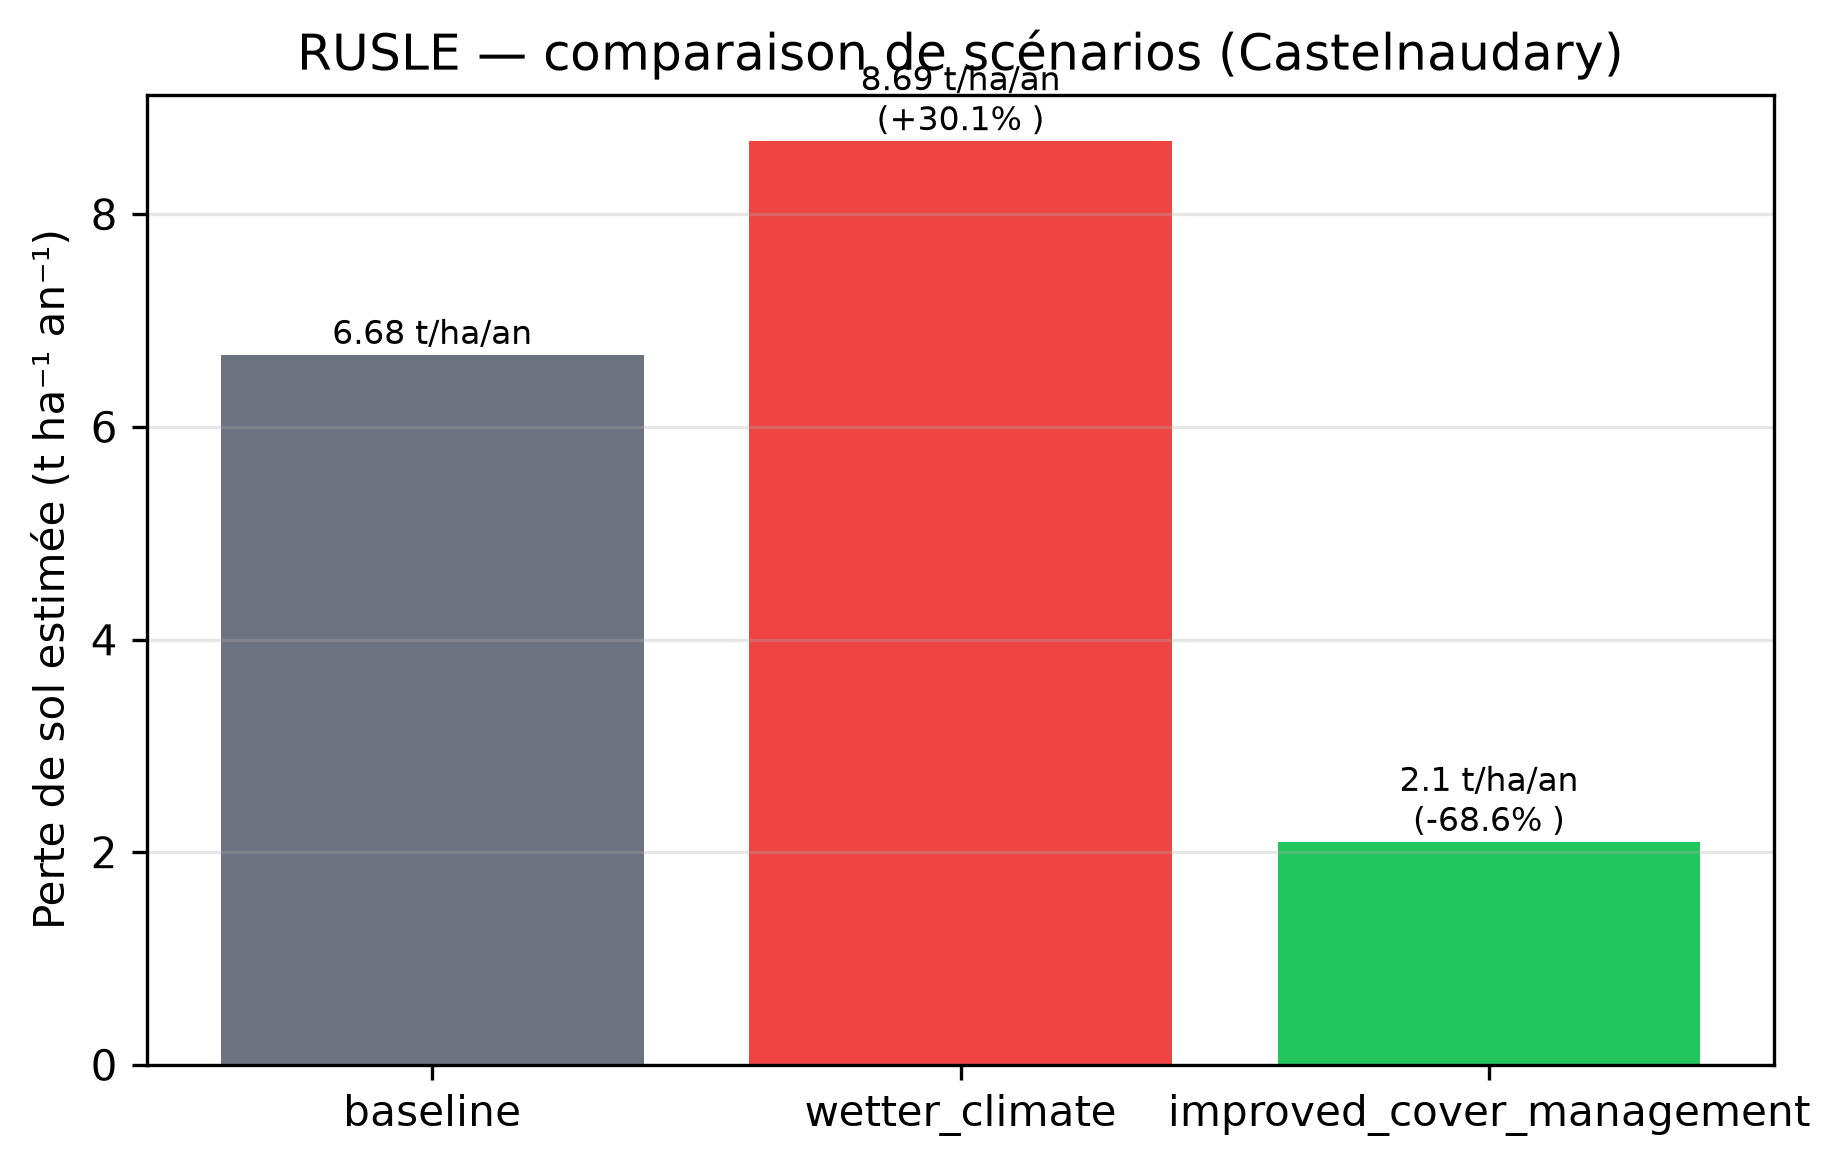

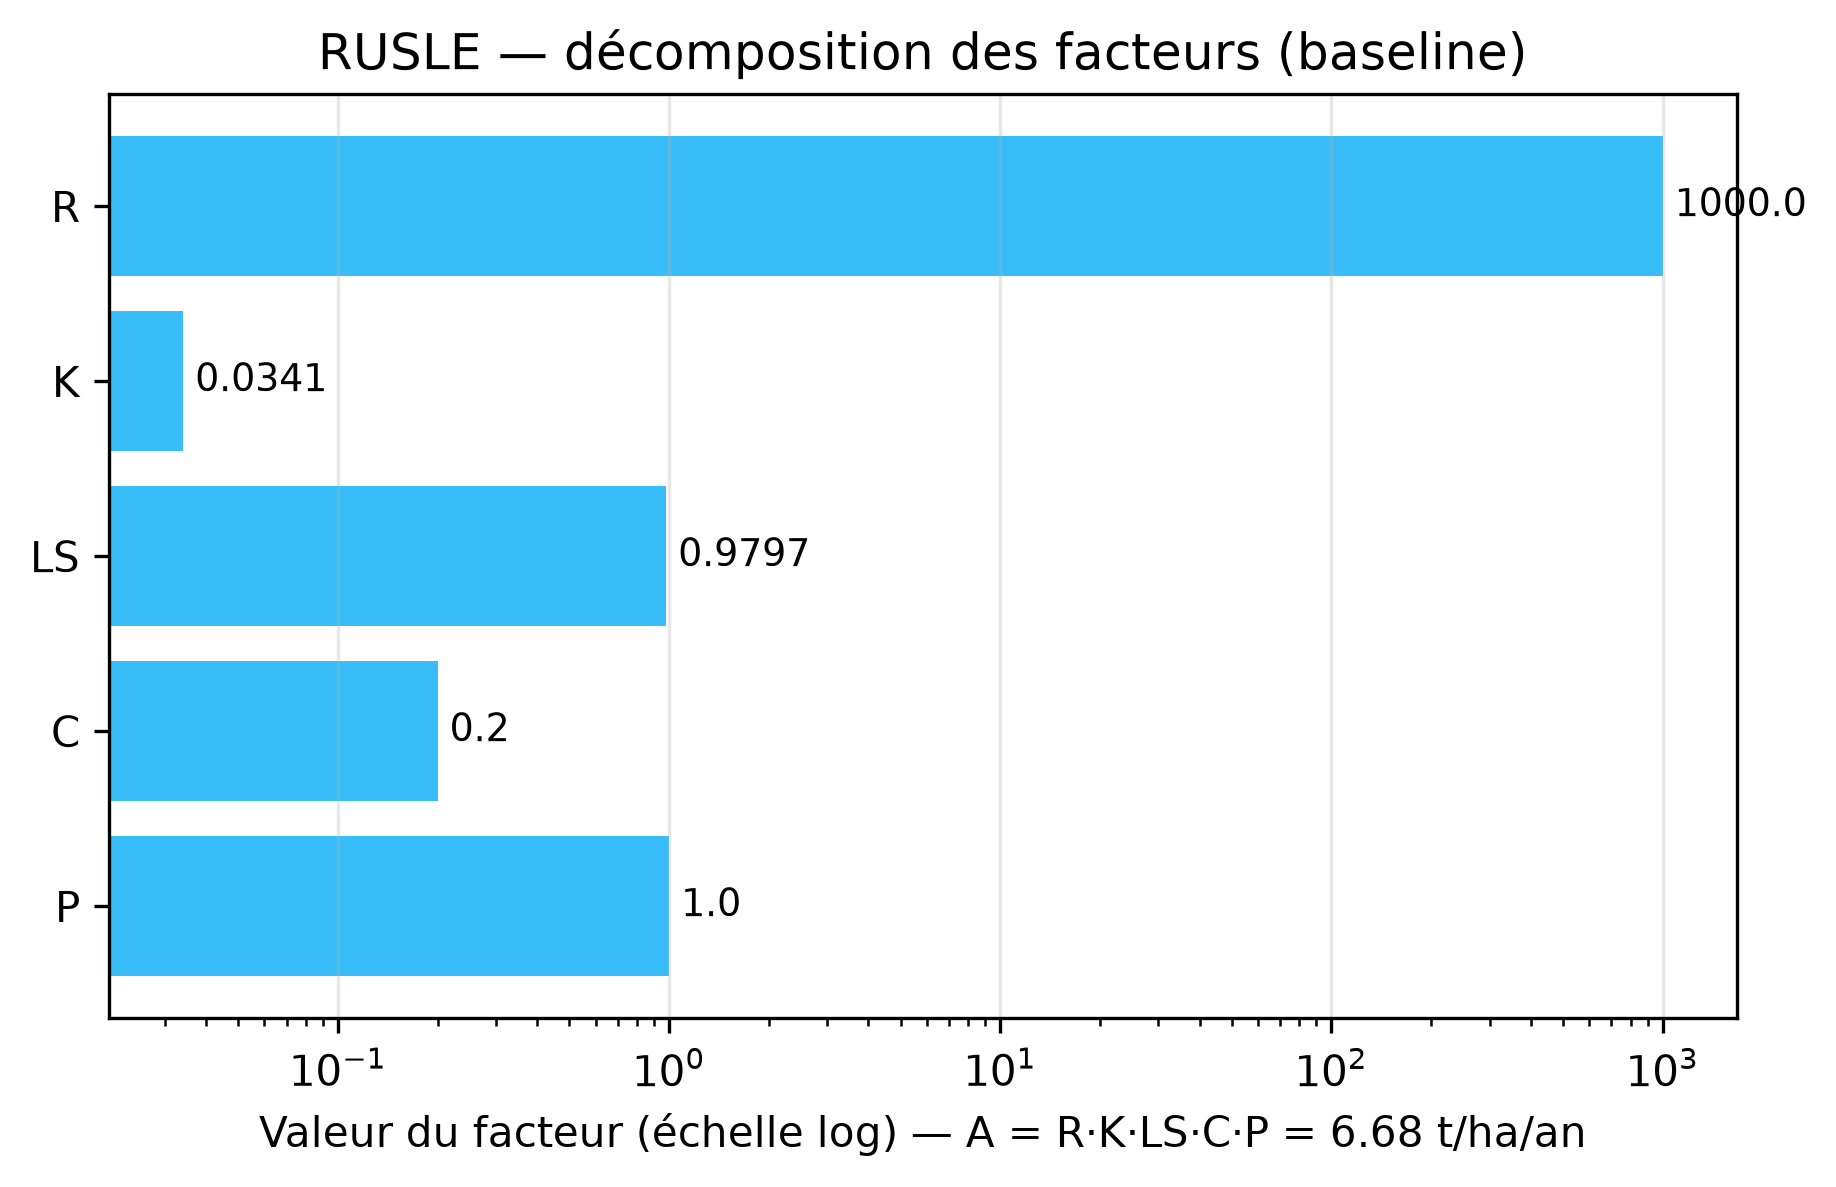

In [6]:
from IPython.display import Image, display
FIG = ROOT / "reports" / "soil-intelligence" / "figures"
display(Image(filename=str(FIG / "01_scenario_comparison.png")))
display(Image(filename=str(FIG / "02_factor_breakdown.png")))

## 5. Sensitivity (tornado) and parameter-uncertainty band

One-at-a-time sensitivity over each factor's documented range (baseline held for the others), and the plausible output band from the combined parameter ranges.

In [7]:
tor_df = pd.DataFrame(res["sensitivity_tornado"])[["factor", "low", "high", "A_low", "A_high", "swing"]]
print("Parameter-uncertainty band:",
      f"{res['uncertainty_range']['A_min_t_ha_yr']}–{res['uncertainty_range']['A_max_t_ha_yr']} t/ha/yr")
tor_df

Parameter-uncertainty band: 1.06–106.67 t/ha/yr


,factor,low,high,A_low,A_high,swing
0,LS,0.7467,3.4931,5.09,23.82,18.73
1,C,0.1000,0.4500,3.34,15.03,11.69
2,R,700.0000,1800.0000,4.68,12.03,7.35
3,P,0.6000,1.0000,4.01,6.68,2.67
4,K,0.0338,0.0377,6.62,7.39,0.77


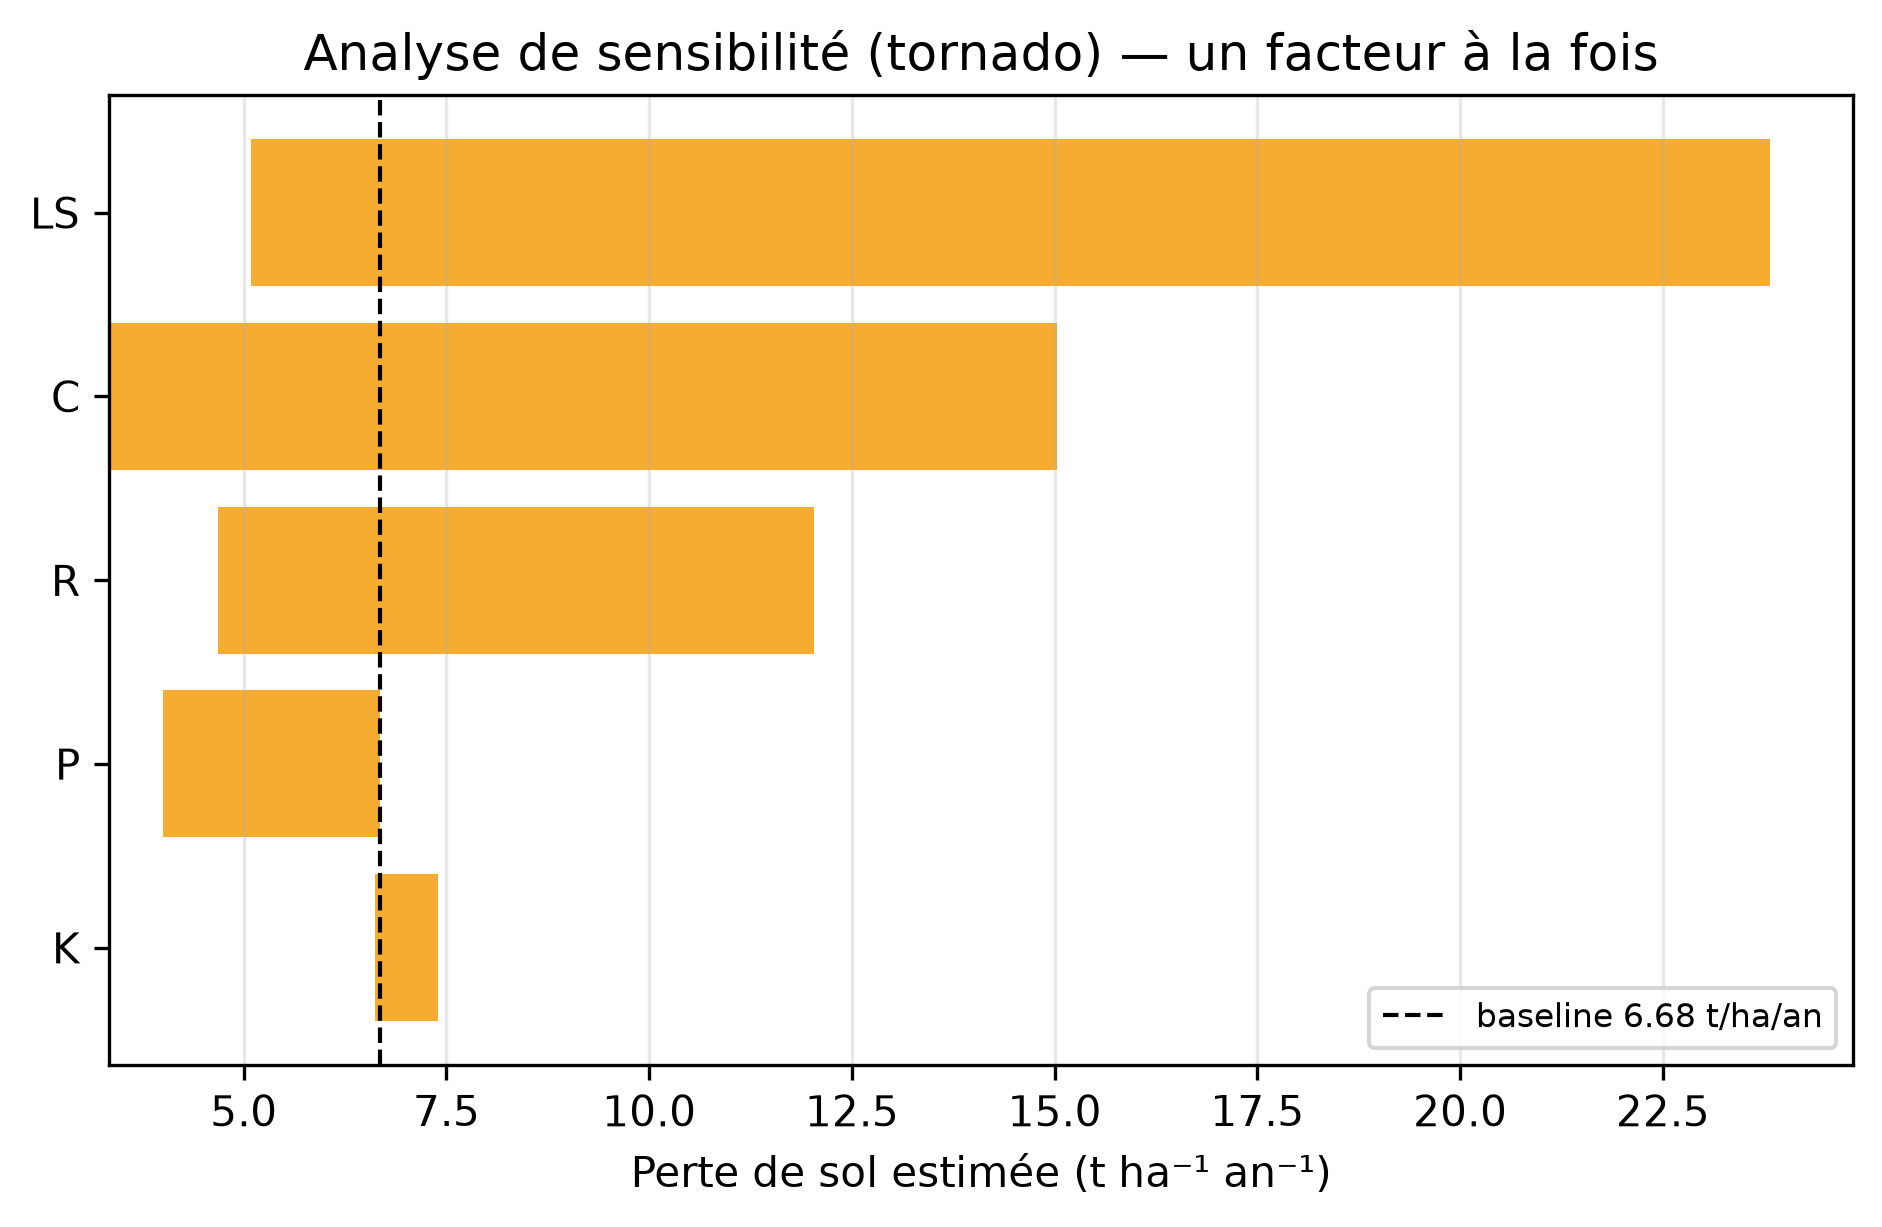

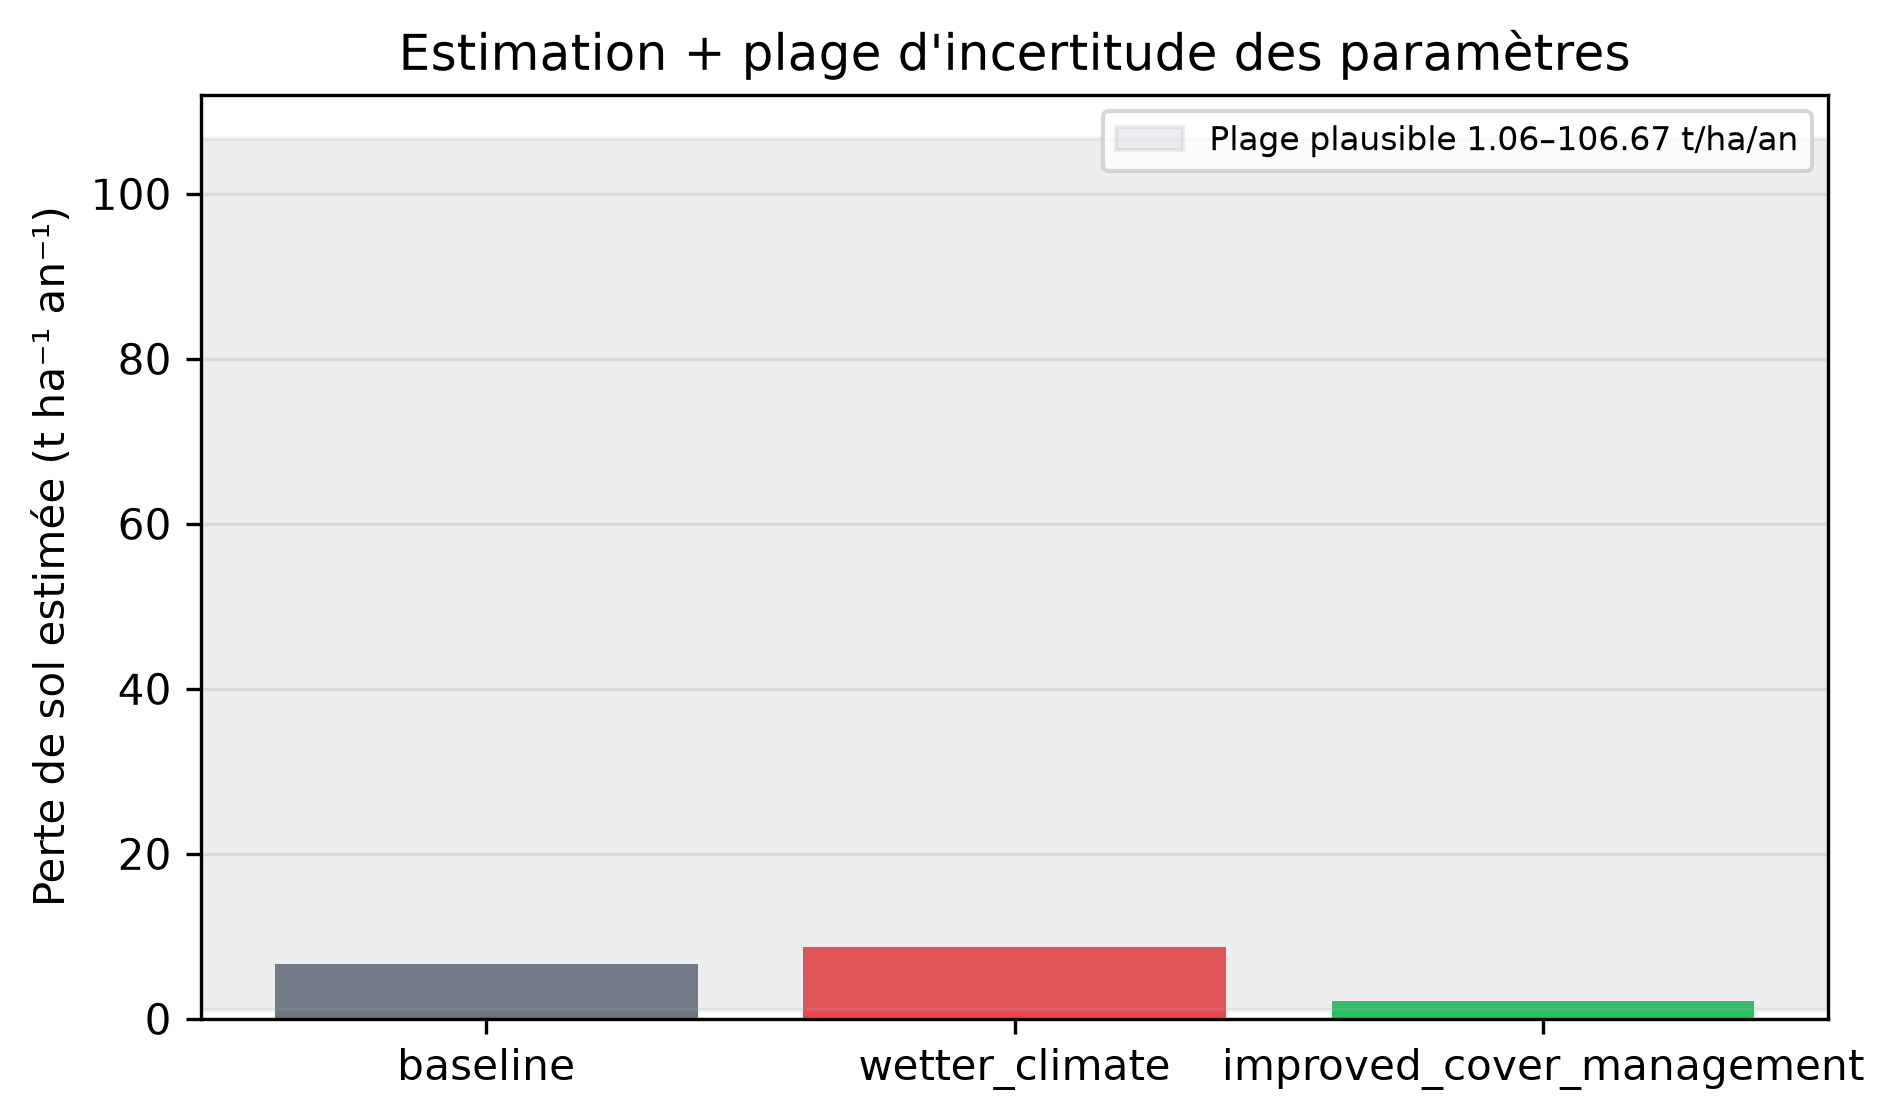

In [8]:
display(Image(filename=str(FIG / "03_tornado_sensitivity.png")))
display(Image(filename=str(FIG / "06_uncertainty_range.png")))

## 6. Historical rainfall exposure and terrain / soil maps

ERA5 2015–2024 annual rainfall and heavy-rain days (projected exposure context for the R scenarios), plus the DEM slope and SoilGrids clay rasters for the study area.

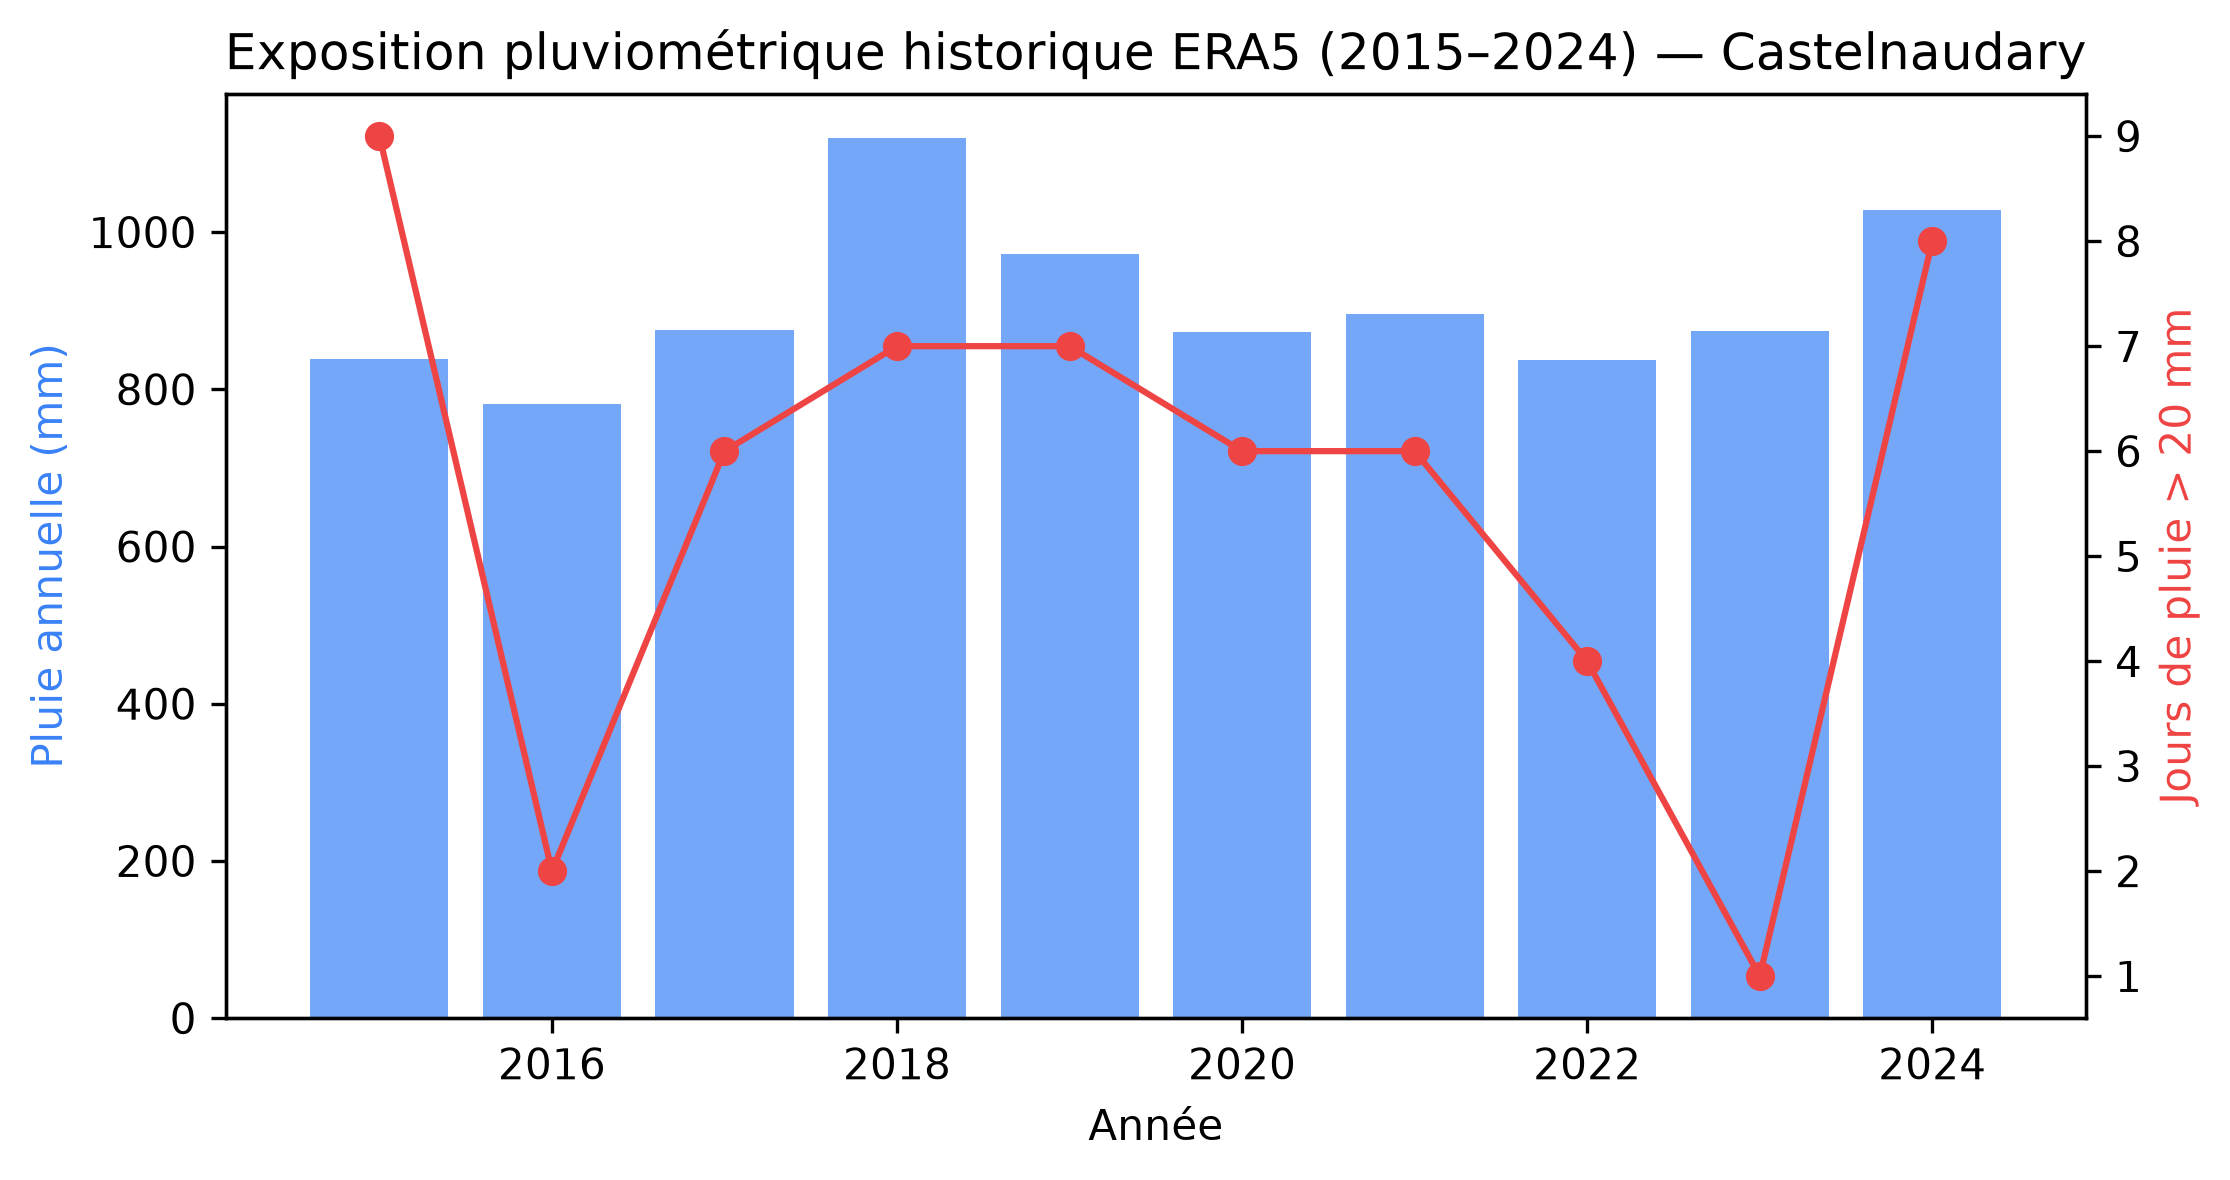

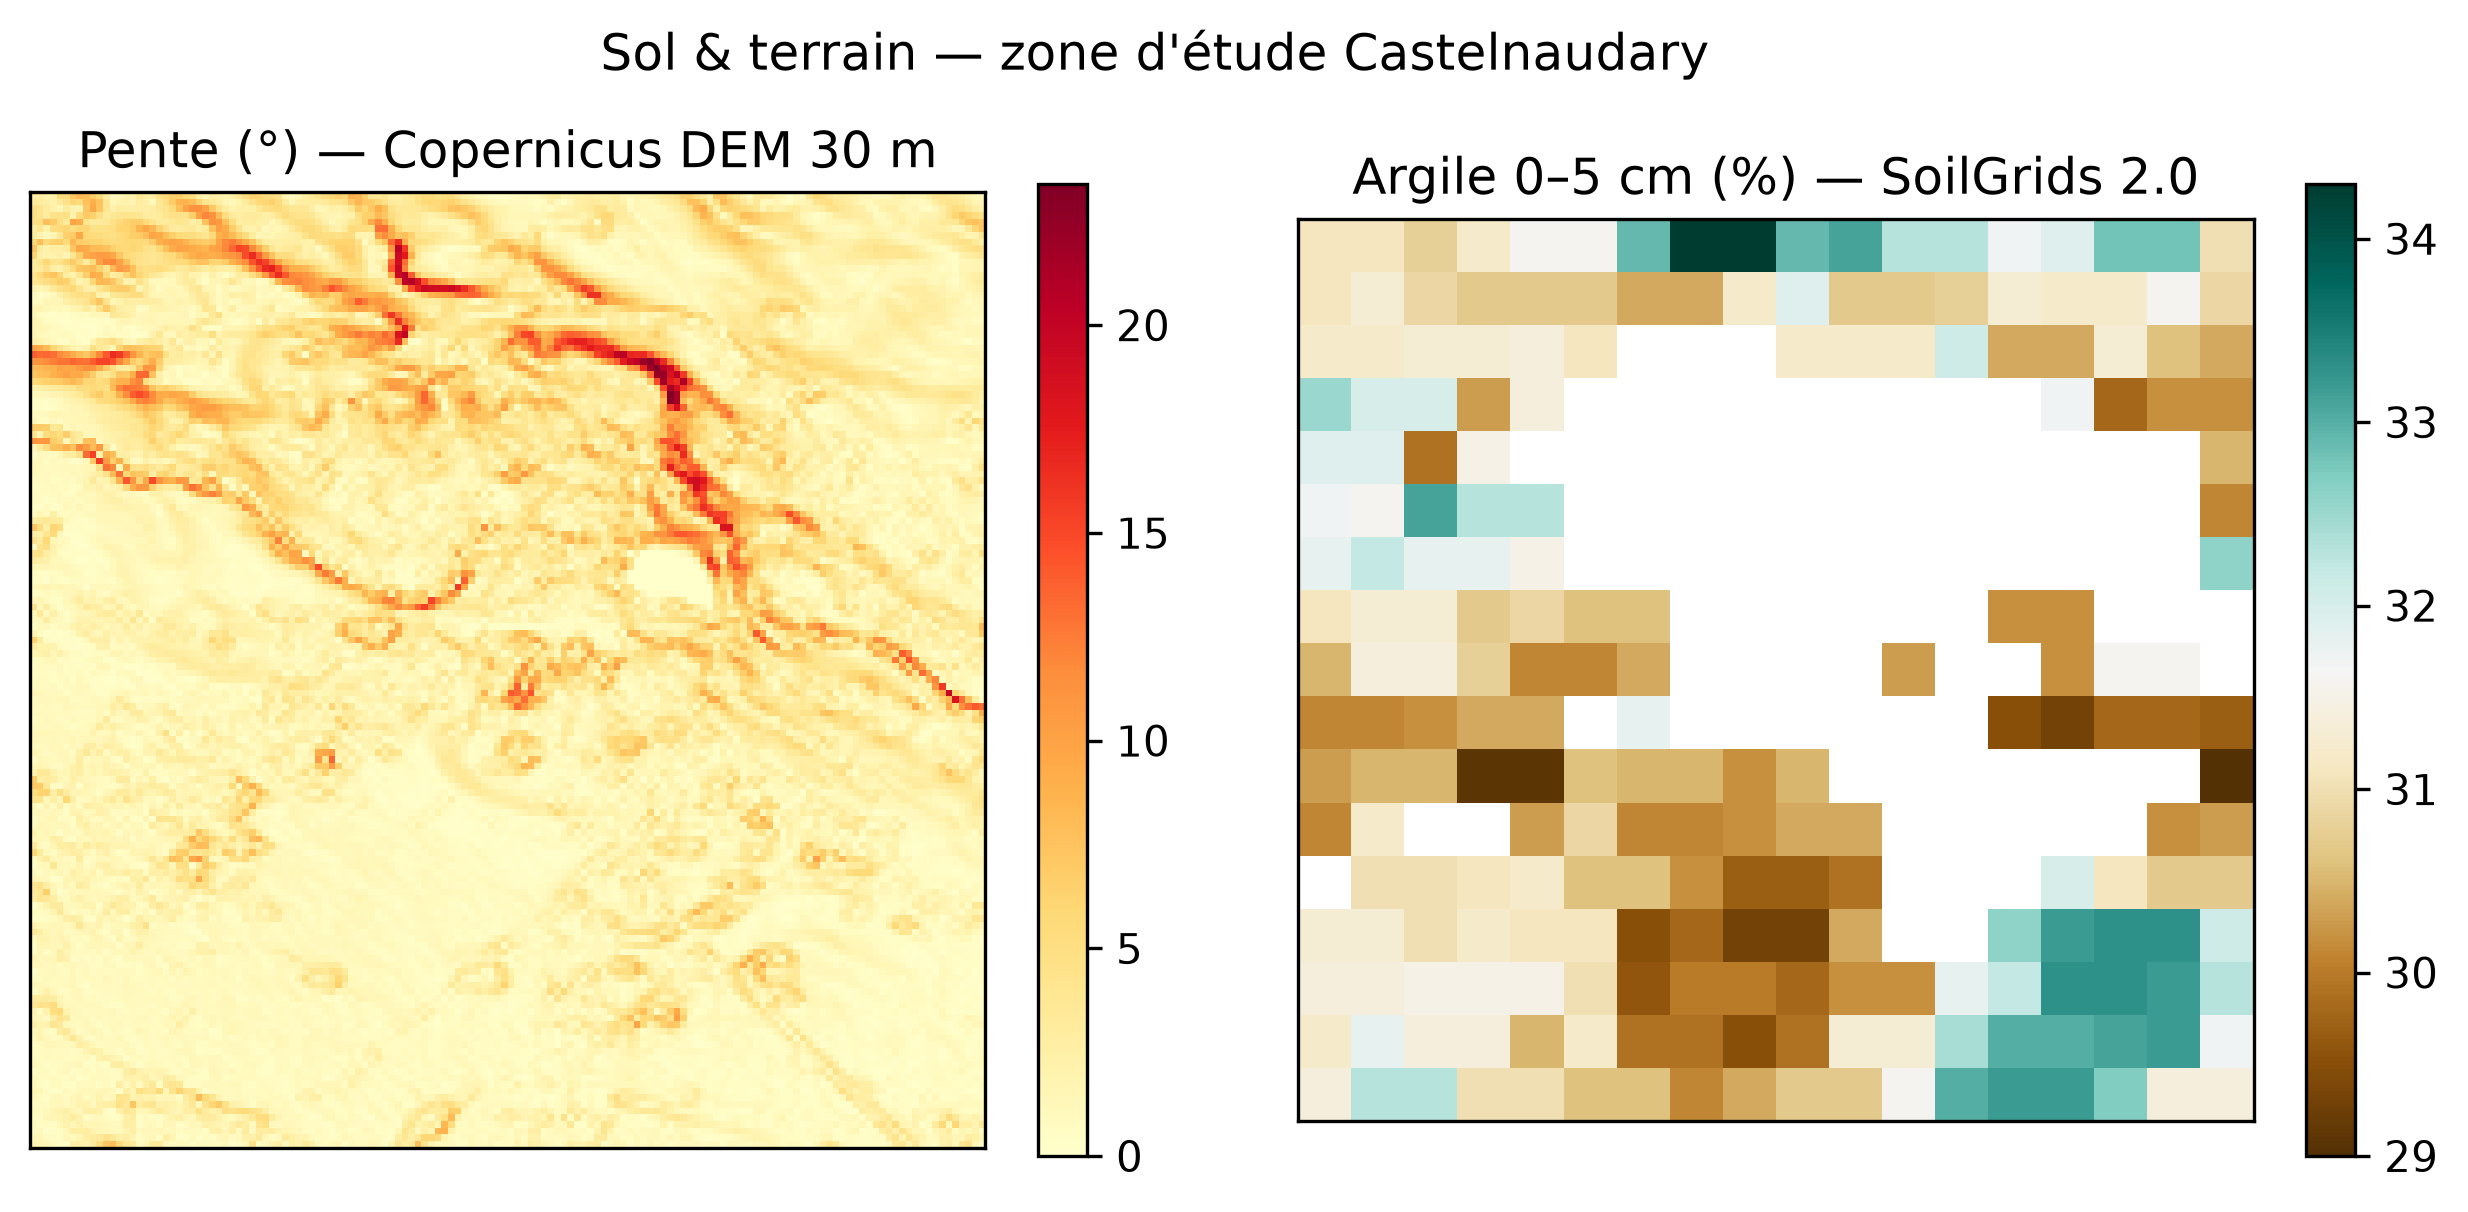

In [9]:
display(Image(filename=str(FIG / "04_rainfall_exposure_timeseries.png")))
display(Image(filename=str(FIG / "05_soil_slope_maps.png")))

## 7. Working API sample responses

The bounded `/geo` endpoints, exercised in-process via FastAPI's `TestClient`. The `coverage` field makes explicit that the prototype serves the validated Castelnaudary study area; locations outside the bounding box return `422 out_of_coverage` instead of pretending the local dataset is nationwide.

In [10]:
import json
from fastapi.testclient import TestClient
from src.api.main import app
from src.geo import soil_intelligence as si

client = TestClient(app)
lat, lon = si.STUDY_AREA["lat"], si.STUDY_AREA["lon"]

# GET /geo/layers
layers = client.get("/geo/layers").json()
print("GET /geo/layers ->", len(layers["layers"]), "layers:",
      [l["layer_id"] for l in layers["layers"]])

/home/ubuntu/Downloads/LegumAmies/.venv/lib/python3.12/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


GET /geo/layers -> 5 layers: ['rpg_2024', 'admin_commune', 'soilgrids_clay', 'copernicus_dem', 'sentinel2_ndvi']


In [11]:
# GET /geo/soil (in coverage)
soil_resp = client.get("/geo/soil", params={"lat": lat, "lon": lon}).json()
print("GET /geo/soil (in coverage):")
print(json.dumps(soil_resp["modelled"][0], indent=2)[:700])

# GET /geo/soil (out of coverage -> 422)
oob = client.get("/geo/soil", params={"lat": 48.8566, "lon": 2.3522})
print("\nGET /geo/soil (Paris, out of coverage):", oob.status_code, "->",
      oob.json()["detail"]["error"])

GET /geo/soil (in coverage):
{
  "depth_cm": "0-5",
  "clay_pct": 31.1,
  "sand_pct": 26.3,
  "silt_pct": 42.6,
  "soil_organic_carbon_g_per_kg": 40.9,
  "ph_h2o": 7.43,
  "provenance": {
    "source": "ISRIC SoilGrids 2.0",
    "data_kind": "modelled_soil_property",
    "url": null,
    "vintage": "2020",
    "crs": "EPSG:4326",
    "resolution": "250 m",
    "licence": "CC-BY 4.0",
    "attribution": "ISRIC \u2014 World Soil Information",
    "retrieved_at_utc": null,
    "uncertainty": "250 m modelled estimate; confirm with a soil test"
  }
}

GET /geo/soil (Paris, out of coverage): 422 -> out_of_coverage


In [12]:
# POST /geo/soil-risk (in coverage)
body = {"location": {"field_id": "demo-castelnaudary", "latitude": lat, "longitude": lon},
        "exposure": {}}
risk = client.post("/geo/soil-risk", json=body).json()
print("POST /geo/soil-risk ->")
print("  coverage        :", risk["coverage"])
print("  model_version   :", risk["model_version"])
print("  vulnerability   :", risk["vulnerability_index"]["score_0_100"], risk["vulnerability_index"]["band"])
print("  RUSLE baseline  :", risk["rusle_baseline"]["soil_loss_t_ha_yr"], "t/ha/yr")
print("  scenarios       :", [(s["scenario"], s["soil_loss_t_ha_yr"], s["pct_vs_baseline"]) for s in risk["scenarios"]])
print("  tornado order   :", [t["factor"] for t in risk["sensitivity_tornado"]])
print("  uncertainty band:", risk["uncertainty_range"])

POST /geo/soil-risk ->
  coverage        : castelnaudary_study_area
  model_version   : rusle-1.0.0
  vulnerability   : 40.5 modéré
  RUSLE baseline  : 6.68 t/ha/yr
  scenarios       : [('baseline', 6.68, 0.0), ('wetter_climate', 8.69, 30.1), ('improved_cover_management', 2.1, -68.6)]
  tornado order   : ['LS', 'C', 'R', 'P', 'K']
  uncertainty band: {'A_min_t_ha_yr': 1.06, 'A_max_t_ha_yr': 106.67}


## 8. Remaining data gaps and what is ready for frontend integration

**Recorded assumptions / data gaps (never silently zeroed):**

In [13]:
for a in res["assumptions"]:
    print("•", a)
print("• R-factor is literature-derived (ESDAC raster needs login); confirm with local R before operational use.")
print("• SoilGrids is a 250 m modelled estimate; confirm with a field soil test.")
print("• LS uses an assumed representative slope length (100 m; varied 50–150 m in sensitivity).")

• Plough-layer OC = depth-weighted 0-15 cm (0-5 & 5-15 cm SoilGrids).
• Slope length not measured; 100 m assumed (varied 50-150 m).
• R-factor literature-derived (Panagos 2015); scenario range used.
• R-factor is literature-derived (ESDAC raster needs login); confirm with local R before operational use.
• SoilGrids is a 250 m modelled estimate; confirm with a field soil test.
• LS uses an assumed representative slope length (100 m; varied 50–150 m in sensitivity).


**Ready for frontend integration (no React changes made in this branch):**

- `GET /geo/layers` — map layer catalogue with legends, CRS, provenance and live-service flags.
- `GET /geo/soil?lat=&lon=` — modelled soil properties with provenance; `422 out_of_coverage` outside the study area.
- `POST /geo/soil-risk` — vulnerability index + RUSLE baseline + scenarios + tornado sensitivity + uncertainty band + parameters + assumptions + sources, with an explicit `coverage` field and `model_version`.
- Static artifacts in `reports/soil-intelligence/` (`baseline_results.json`, `scenario_results.csv`, `parameters.csv`, `sensitivity_tornado.csv`, `run_metadata.json`, `RESULTS.md`, six PNG+SVG figures) can be served directly to a dashboard.
- Existing ClimateShield `/assess` and Bedrock `/advisor/ask` contracts are unchanged (additive router only); nothing is redeployed to AWS in this branch.